In [4]:

import matplotlib.pyplot as plt
from matplotlib import rcParams
from typing import Dict, List, Union

# use None instead of an empty dictionary as a default argument.
def my_plotter(x: List[float],
               y: Union[List[float], List[List[float]]],
               layout: Dict = None,
               names: List[str] = None) -> None:

    #create an empty layout dictionary if no settings are provided.
    if layout is None:
        layout = {}

    # recognize both a single curve and multiple curves.
    if len(y) > 0 and isinstance(y[0], (int, float)):
        y = [y]

    #figure size can now be customized through layout.
    plt.figure(figsize=layout.get('figsize', (8, 4)))

    lines = []
    show_legend = True if names is not None else False

    #line parameters are no longer hard-coded.
    plot_kwargs = {
        'linestyle': layout.get('linestyle', 'solid'),
        'linewidth': layout.get('linewidth', 4)
    }

    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError(
                "Length of names is not matching with number of plotted y lists."
            )

    # Keep the original loop for plotting multiple curves.
    for i, y_item in enumerate(y):

        #make a separate copy of line settings for each curve.
        current_kwargs = plot_kwargs.copy()

        if show_legend:
            current_kwargs['label'] = names[i]

        #allow users to specify colors for different curves.
        if 'colors' in layout:
            current_kwargs['color'] = (
                layout['colors'][i % len(layout['colors'])]
            )

        _line = plt.plot(x, y_item, **current_kwargs)
        lines.append(_line)

    if show_legend:
        #legend font size is customizable.
        plt.legend(
            fontsize=layout.get('legend_fontsize', 16)
        )

    if 'title' in layout:
        #title font size and spacing are customizable.
        plt.title(
            layout['title'],
            fontsize=layout.get('title_fontsize', 20),
            pad=layout.get('title_pad', 30)
        )

    if 'x_label' in layout:
        #x-axis label font size is customizable.
        plt.xlabel(
            layout['x_label'],
            fontsize=layout.get('label_fontsize', 16),
            labelpad=layout.get('label_pad', 20)
        )

    if 'y_label' in layout:
        plt.ylabel(
            layout['y_label'],
            fontsize=layout.get('label_fontsize', 16),
            labelpad=layout.get('label_pad', 20)
        )

    if layout.get('grid', False):
        plt.grid(True, linestyle='--', alpha=0.5)

    #keep the original horizontal reference line at y = 0.
    ax = plt.gca()
    ax.axhline(
        linestyle='--',
        color='black',
        linewidth=1
    )

    #automatically adjust spacing between plot elements.
    plt.tight_layout()

    plt.show()


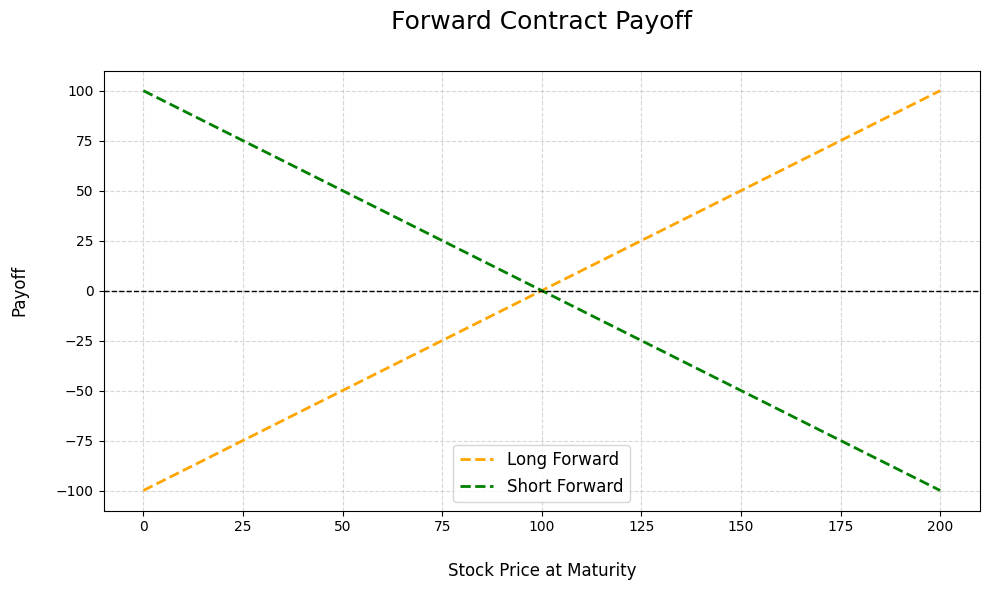

In [5]:

import numpy as np

# Define the strike price 
strike = 100

# Generate stock prices 
x_stock_price = np.arange(0, 200, 0.01)

# Calculate long forward payoff
y_forward_payoff = x_stock_price - strike

# Calculate short forward payoff 
y_forward_payoff__short = -y_forward_payoff

# Set custom plotting parameters 
custom_layout = {
    'title': 'Forward Contract Payoff',
    'x_label': 'Stock Price at Maturity',
    'y_label': 'Payoff',
    'figsize': (10, 6),
    'linewidth': 2,
    'linestyle': '--', # - or --
    'colors': ['orange', 'green'],
    'title_fontsize': 18,
    'legend_fontsize': 12,
    'label_fontsize': 12,
    'grid': True
}

# Call our modified function 
my_plotter(
    x_stock_price,
    [y_forward_payoff, y_forward_payoff__short],
    layout=custom_layout,
    names=['Long Forward', 'Short Forward']
)
